<a href="https://colab.research.google.com/github/draganmihaela/ML-Seminar-DraganMihaela/blob/main/LP_8_2_Decission_Tree_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Seminar 4 - Arbori de regresie

Obiective:
După finalizarea acestui laborator, veți putea:
- sa utilizați scikit-learn pentru a implementa arbori de regresie
- sa creați un model, sa il antrenați, sa il testați și sa il utilizați

In [1]:
import pandas as pd
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import train_test_split

**CITIREA DATELOR**

**Despre setul de date**

Sunt colectate date despre diferite zone din Boston pentru a crea un model care sa pota prezice prețul mediu al caselor pentru acea zonă.
Setul de date avea informații despre zone/orașe, nu despre case individuale:
- CRIM: Crimă pe cap de locuitor
- ZN: Proporția de teren rezidențial zonat pentru loturi de peste 25.000 sq.ft.
- INDUS: Proporția de hectare comerciale non-retail pe oraș
- CHAS: variabilă dummy Charles River (= 1 dacă delimitează râul; 0 în caz contrar)
- NOX: concentrație de oxizi nitrici (părți la 10 milioane)
- RM: Numărul mediu de camere pe locuință
- Vârsta: Proporția unităților ocupate de proprietar construite înainte de 1940
- DIS: Distanțe ponderate până la cinci centre de angajare din Boston
- RAD: Indice de accesibilitate la autostrăzile radiale
- TAXĂ: Cota de impozit pe proprietate la valoarea completă pentru 10.000 USD
- PTRAIO: Raport elev-profesor pe oraș
- LSTAT: Statutul procentual mai scăzut al populației
- MEDV: Valoarea medie a caselor ocupate de proprietari în 1000 de dolari

    https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-ML0101EN-SkillsNetwork/labs/Module%203/data/real_estate_data.csv
        

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [11]:
data = pd.read_csv("/content/drive/MyDrive/Machine Learning 2026/real_estate_data.csv")
data.head()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,LSTAT,MEDV
0,0.00632,18.0,2.31,0.0,0.538,6.575,65.2,4.0900,1,296,15.3,4.98,24.0
1,0.02731,0.0,7.07,0.0,0.469,6.421,78.9,4.9671,2,242,17.8,9.14,21.6
2,0.02729,0.0,7.07,0.0,0.469,7.185,61.1,4.9671,2,242,17.8,4.03,34.7
3,0.03237,0.0,2.18,0.0,0.458,6.998,45.8,6.0622,3,222,18.7,2.94,33.4
4,0.06905,0.0,2.18,0.0,0.458,7.147,54.2,6.0622,3,222,18.7,NaN,36.2


In [12]:
data.describe()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,LSTAT,MEDV
count,486.000000,486.000000,486.000000,486.000000,506.000000,506.000000,486.000000,506.000000,506.000000,506.000000,506.000000,486.000000,506.000000
mean,3.611874,11.211934,11.083992,0.069959,0.554695,6.284634,68.518519,3.795043,9.549407,408.237154,18.455534,12.715432,22.532806
std,8.720192,23.388876,6.835896,0.255340,0.115878,0.702617,27.999513,2.105710,8.707259,168.537116,2.164946,7.155871,9.197104
min,0.006320,0.000000,0.460000,0.000000,0.385000,3.561000,2.900000,1.129600,1.000000,187.000000,12.600000,1.730000,5.000000
25%,0.081900,0.000000,5.190000,0.000000,0.449000,5.885500,45.175000,2.100175,4.000000,279.000000,17.400000,7.125000,17.025000
50%,0.253715,0.000000,9.690000,0.000000,0.538000,6.208500,76.800000,3.207450,5.000000,330.000000,19.050000,11.430000,21.200000
75%,3.560263,12.500000,18.100000,0.000000,0.624000,6.623500,93.975000,5.188425,24.000000,666.000000,20.200000,16.955000,25.000000
max,88.976200,100.000000,27.740000,1.000000,0.871000,8.780000,100.000000,12.126500,24.000000,711.000000,22.000000,37.970000,50.000000


In [13]:
data.shape

(506, 13)

**Preprocesarea datelor**

In [14]:
data.isna().sum()

,0
CRIM,20
ZN,20
INDUS,20
CHAS,20
NOX,0
RM,0
AGE,20
DIS,0
RAD,0
TAX,0


In [15]:
data.dropna(inplace=True)

In [16]:
data.isna().sum()

,0
CRIM,0
ZN,0
INDUS,0
CHAS,0
NOX,0
RM,0
AGE,0
DIS,0
RAD,0
TAX,0


**Impartirea setului de date in var explicative si variabila target "MEDV"**

In [17]:
X = data.drop(columns=["MEDV"])
y = data["MEDV"]

In [ ]:
X.head()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,LSTAT
0,0.00632,18.0,2.31,0.0,0.538,6.575,65.2,4.0900,1,296,15.3,4.98
1,0.02731,0.0,7.07,0.0,0.469,6.421,78.9,4.9671,2,242,17.8,9.14
2,0.02729,0.0,7.07,0.0,0.469,7.185,61.1,4.9671,2,242,17.8,4.03
3,0.03237,0.0,2.18,0.0,0.458,6.998,45.8,6.0622,3,222,18.7,2.94
5,0.02985,0.0,2.18,0.0,0.458,6.430,58.7,6.0622,3,222,18.7,5.21


In [18]:
y.head()

,MEDV
0,24.0
1,21.6
2,34.7
3,33.4
5,28.7


**Impartirea setului de date in doua: un set de antrenare si unul de testare**

In [19]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.2, random_state=1)

**Crearea arborelui de regresie**

**Arborii de regresie** sunt implementati folosind  *DecisionTreeRegressor* from *sklearn.tree*

Parametrii importanti sunt

- criterion: {"squared error", "mse", "friedman_mse", "mae", "poisson"} - functia folosita pentru masurarea erorii
- max_depth - cat de mare sa fie arborele
- min_samples_split - numarul minim de esantioane pentru a splita un nod
- min_samples_leaf - numarul minim de esantioane pe care le poate contine o frunza
- max_features: {"auto", "sqrt", "log2"} - numarul de atribute ce vor fi examinate pentru a le alege pe cele mai bune, pentru a mari viteza de rulare a algoritmului

Mai întâi să începem prin a crea un obiect DecisionTreeRegressor, setând parametrul criteriu la squared_error pentru Squared Error

Adâncimea optimă: 18
Cel mai mic MSE mediu: 21.2686


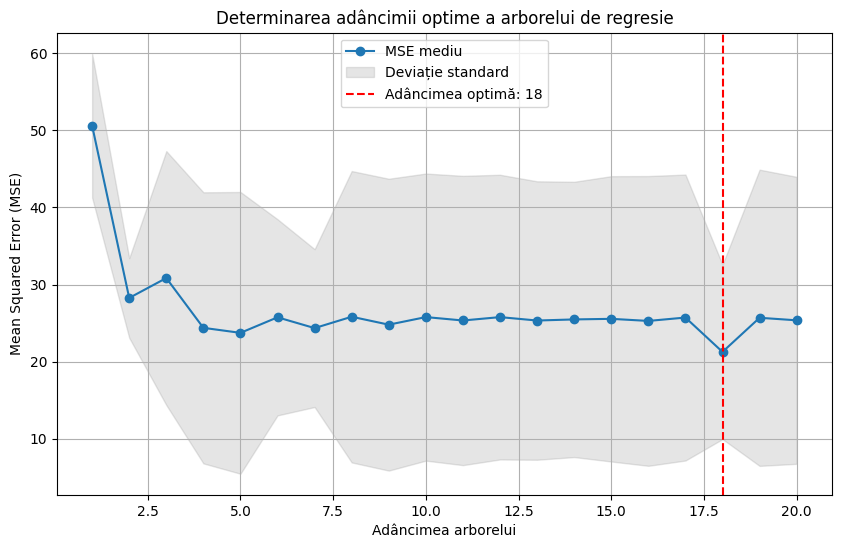

In [20]:
from sklearn.metrics import make_scorer, mean_squared_error
from sklearn.model_selection import cross_val_score
import matplotlib.pyplot as plt
import numpy as np

# Intervalul de adâncimi de testat
depth_range = range(1, 21)

# Liste pentru scoruri
mean_scores = []  # Scorul mediu pentru fiecare adâncime
std_scores = []   # Deviația standard pentru fiecare adâncime

# Calcularea scorurilor de validare încrucișată pentru fiecare adâncime
for depth in depth_range:
    model = DecisionTreeRegressor(criterion = 'squared_error', max_depth=depth, random_state=42)
    scores = cross_val_score(model, X_train, y_train, cv=5, scoring='neg_mean_squared_error')
    mean_scores.append(-np.mean(scores))  # Transformăm scorurile negative în MSE pozitive
    std_scores.append(np.std(scores))

# Găsirea adâncimii optime
optimal_depth = depth_range[np.argmin(mean_scores)]
print(f"Adâncimea optimă: {optimal_depth}")
print(f"Cel mai mic MSE mediu: {min(mean_scores):.4f}")

# Vizualizarea scorurilor
plt.figure(figsize=(10, 6))
plt.plot(depth_range, mean_scores, label='MSE mediu', marker='o')
plt.fill_between(
    depth_range,
    np.array(mean_scores) - np.array(std_scores),
    np.array(mean_scores) + np.array(std_scores),
    color='gray',
    alpha=0.2,
    label='Deviație standard'
)
plt.axvline(optimal_depth, color='r', linestyle='--', label=f"Adâncimea optimă: {optimal_depth}")
plt.xlabel('Adâncimea arborelui')
plt.ylabel('Mean Squared Error (MSE)')
plt.title('Determinarea adâncimii optime a arborelui de regresie')
plt.legend()
plt.grid()
plt.show()

In [21]:
regression_tree = DecisionTreeRegressor(criterion = 'squared_error', max_depth=4)

In [22]:
#antrenarea
regression_tree.fit(X_train, y_train)

DecisionTreeRegressor(max_depth=4)

In [23]:
# calcului valorii R2 pe setul de testare
regression_tree.score(X_test, y_test)

0.7205804758678532

In [24]:
#Eroarea medie calculata pe setul de testare, care este eroarea medie în predicția valorii medii a casei
y_pred = regression_tree.predict(X_test)

print("$",(y_pred - y_test).abs().mean()*1000)

$ 3379.8487804323863


In [25]:
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error

# Masuri ale potrivirii modelului
print(f"Mean Squared Error(MSE) : {mean_squared_error(y_test, y_pred)}")
print(f"Mean Absolute Error (MAE): {mean_absolute_error(y_test, y_pred)}")

Mean Squared Error(MSE) : 24.93597051453634
Mean Absolute Error (MAE): 3.3798487804323862


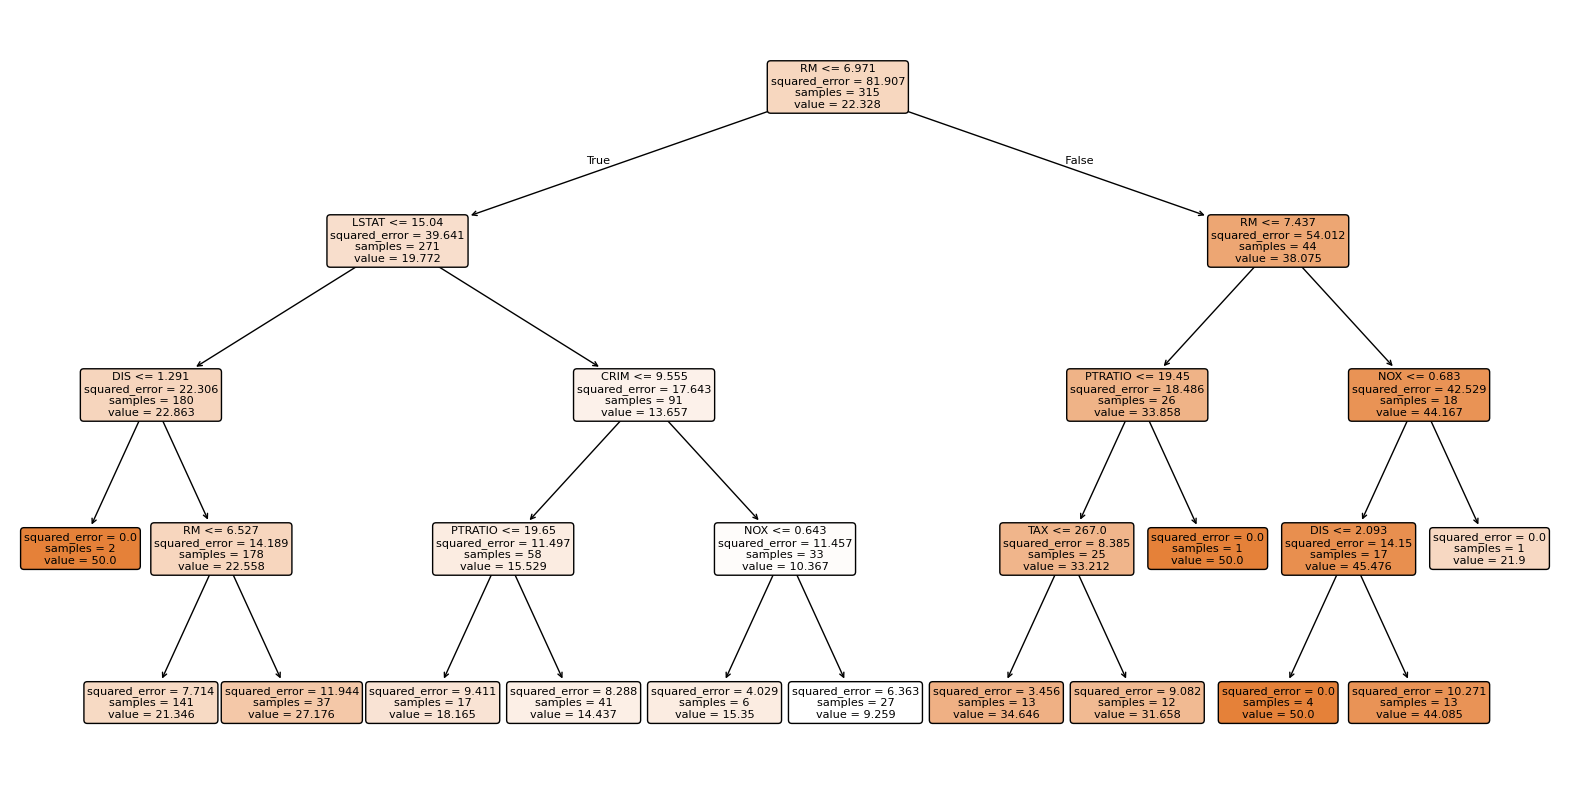

In [26]:
from sklearn.tree import DecisionTreeRegressor, plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(20, 10))
plot_tree(regression_tree, filled=True, feature_names=['CRIM', 'ZN', 'INDUS', 'CHAS','NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX', 'PTRATIO', 'LSTAT'], rounded=True)
plt.show()